<a href="https://colab.research.google.com/github/raksha7259608-wq/rakshaa/blob/main/mini%20project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

🌱 PLANTCARE AI
Libraries loaded successfully!

✅ Dataset created successfully!
Dataset size: (1000, 9)


,Plant_Type,Plant_Age_Days,Temperature_C,Humidity_Percent,Soil_Moisture_Percent,Sunlight_Hours,Water_ml_Day,Fertilizer_g_Week,Plant_Height_cm
0,Beans,104,38.360901,38.738283,55.183041,8.925405,619.618061,4.235963,48.663052
1,Spinach,72,23.790567,49.460713,40.142163,12.687901,681.766638,15.850795,30.402514
2,Chilli,137,17.535521,53.316509,27.573358,9.163343,512.527131,3.738146,43.570451
3,Spinach,124,27.146794,82.288418,32.561832,11.721933,575.836588,1.333197,39.910170
4,Spinach,41,21.419414,48.119392,31.045667,7.156080,130.939173,19.971216,26.513330



DATA PREPROCESSING
Training samples: 800
Testing samples: 200

🌲 RANDOM FOREST TRAINING
Random Forest Results
MAE : 2.397
RMSE : 3.093
R² : 0.897

🧠 DEEP LEARNING ANN TRAINING


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Deep Learning ANN Results
MAE : 3.128
RMSE : 3.95
R² : 0.832

📊 MODEL COMPARISON


,Metric,Random Forest,Deep Learning ANN
0,MAE,2.397,3.128
1,RMSE,3.093,3.950
2,R²,0.897,0.832



🏆 Best Model: Random Forest


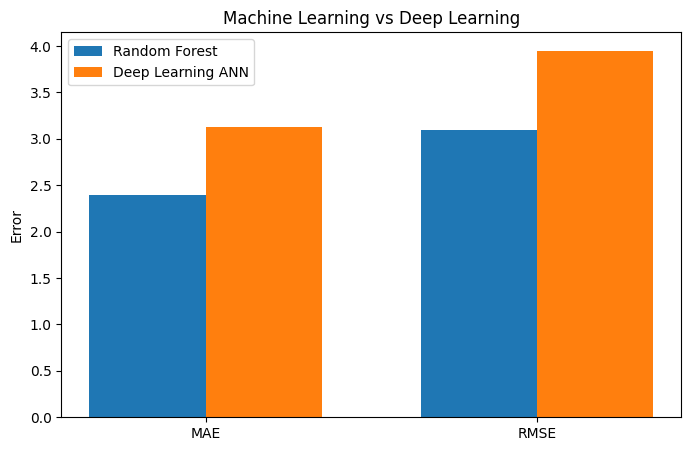

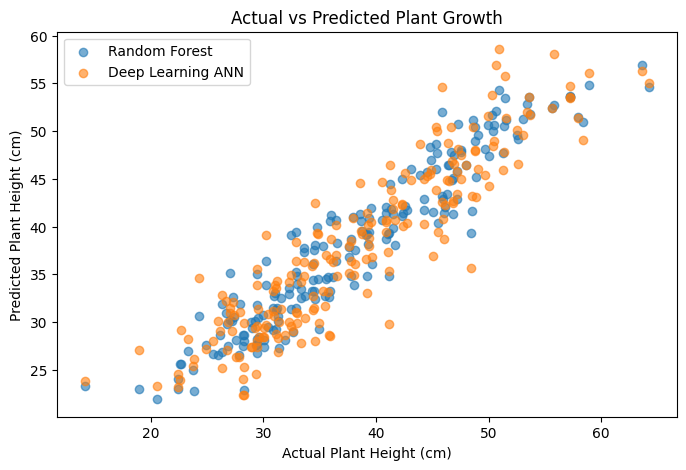

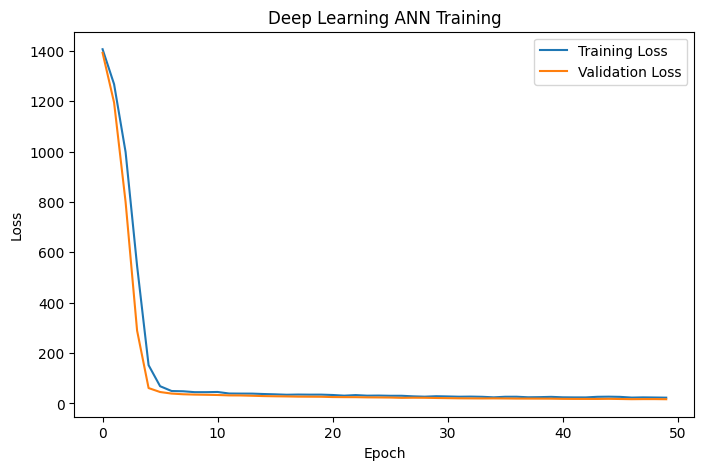

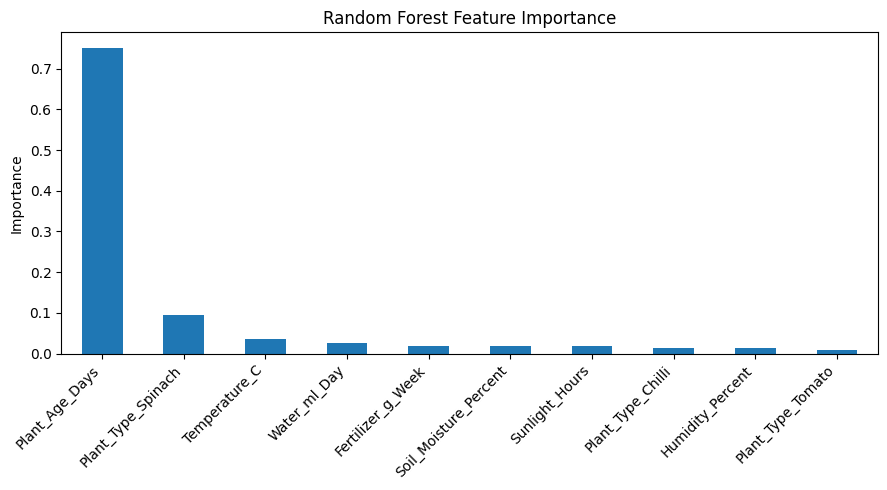


🌱 PLANTCARE AI PREDICTION APP



✅ PlantCare AI is ready!
Enter the plant information above and press
🌱 PREDICT PLANT GROWTH.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
import ipywidgets as widgets
from IPython.display import display, clear_output
print("================================================")
print("🌱 PLANTCARE AI")
print("================================================")
print("Libraries loaded successfully!\n")
np.random.seed(42)
n = 1000
plant_types = np.random.choice(["Rose", "Tomato", "Chilli", "Beans", "Spinach"],n)
age = np.random.randint(5, 181, n)
temperature = np.random.uniform(15, 40, n)
humidity = np.random.uniform(30, 95, n)
soil_moisture = np.random.uniform(20, 95, n)
sunlight = np.random.uniform(2, 14, n)
water = np.random.uniform(100, 1000, n)
fertilizer = np.random.uniform(0, 20, n)
plant_factor = {"Rose": 1.00,"Tomato": 1.08,"Chilli": 0.94,"Beans": 1.03,"Spinach": 0.82}
factor = np.array([plant_factor[p] for p in plant_types])
plant_height = (5 + age * 0.16+ np.maximum(0,1 - abs(temperature - 25) / 18) * 7+
np.maximum(0,1 - abs(humidity - 65) / 65 ) * 4+ np.maximum(0,1 - abs(soil_moisture - 60) / 60) *
6+ np.maximum(0, 1 - abs(sunlight - 8) / 8) * 5+ np.maximum( 0,1 - abs(water - 500)/ 500) *
5+ np.maximum(0,1 - abs(fertilizer - 8) / 12) * 3) * factor
plant_height += np.random.normal(0, 2, n)
plant_height = np.maximum(plant_height,1)
df = pd.DataFrame({
    "Plant_Type": plant_types,
    "Plant_Age_Days": age,
    "Temperature_C": temperature,
    "Humidity_Percent": humidity,
    "Soil_Moisture_Percent": soil_moisture,
    "Sunlight_Hours": sunlight,
    "Water_ml_Day": water,
    "Fertilizer_g_Week": fertilizer,
    "Plant_Height_cm": plant_height
})
print("✅ Dataset created successfully!")
print("Dataset size:", df.shape)
display(df.head())
df_encoded = pd.get_dummies(df,columns=["Plant_Type"],dtype=int)
X = df_encoded.drop("Plant_Height_cm",axis=1)
y = df_encoded["Plant_Height_cm"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("\n================================")
print("DATA PREPROCESSING")
print("================================")
print("Training samples:",len(X_train))
print("Testing samples:",len(X_test))
print("\n================================")
print("🌲 RANDOM FOREST TRAINING")
print("================================")
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train,y_train)
rf_prediction = rf_model.predict(X_test)
rf_mae = mean_absolute_error(y_test,rf_prediction)
rf_mse = mean_squared_error(y_test,rf_prediction)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test,rf_prediction)
print("Random Forest Results")
print("MAE :",round(rf_mae, 3))
print("RMSE :",round(rf_rmse, 3))
print("R² :",round(rf_r2, 3))
print("\n================================")
print("🧠 DEEP LEARNING ANN TRAINING")
print("================================")
ann_model = Sequential([
    Dense(64,activation="relu",input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),
    Dense(32,activation="relu"),
    Dense(16,activation="relu"),
    Dense(1)])
ann_model.compile(optimizer="adam",loss="mse",metrics=["mae"])
history = ann_model.fit(X_train_scaled,y_train,epochs=50,batch_size=32,validation_split=0.2,verbose=0)
ann_prediction = ann_model.predict(X_test_scaled,verbose=0).flatten()
ann_mae = mean_absolute_error(y_test,ann_prediction)
ann_mse = mean_squared_error(y_test,ann_prediction)
ann_rmse = np.sqrt(ann_mse)
ann_r2 = r2_score(y_test,ann_prediction)
print("Deep Learning ANN Results")
print("MAE :",round(ann_mae, 3))
print("RMSE :",round(ann_rmse, 3))
print("R² :",round(ann_r2, 3))
print("\n================================")
print("📊 MODEL COMPARISON")
print("================================")
comparison = pd.DataFrame({
    "Metric": ["MAE","RMSE""R²"],
    "Random Forest": [rf_mae,rf_rmse,
        rf_r2
    ],

    "Deep Learning ANN": [
        ann_mae,
        ann_rmse,
        ann_r2
    ]

})


display(
    comparison.round(3)
)


# Determine best model
if ann_mae < rf_mae:

    best_model = "Deep Learning ANN"

else:

    best_model = "Random Forest"


print(
    "\n🏆 Best Model:",
    best_model
)


# =========================
# 7. PERFORMANCE GRAPH
# =========================

plt.figure(
    figsize=(8,5)
)

metrics = [
    "MAE",
    "RMSE"
]

rf_values = [
    rf_mae,
    rf_rmse
]

ann_values = [
    ann_mae,
    ann_rmse
]

x = np.arange(
    len(metrics)
)

width = 0.35


plt.bar(

    x - width/2,

    rf_values,

    width,

    label="Random Forest"

)


plt.bar(

    x + width/2,

    ann_values,

    width,

    label="Deep Learning ANN"

)


plt.xticks(
    x,
    metrics
)

plt.ylabel(
    "Error"
)

plt.title(
    "Machine Learning vs Deep Learning"
)

plt.legend()

plt.show()


# =========================
# 8. ACTUAL VS PREDICTED
# =========================

plt.figure(
    figsize=(8,5)
)


plt.scatter(

    y_test,

    rf_prediction,

    alpha=0.6,

    label="Random Forest"

)


plt.scatter(

    y_test,

    ann_prediction,

    alpha=0.6,

    label="Deep Learning ANN"

)


plt.xlabel(
    "Actual Plant Height (cm)"
)

plt.ylabel(
    "Predicted Plant Height (cm)"
)

plt.title(
    "Actual vs Predicted Plant Growth"
)

plt.legend()

plt.show()


# =========================
# 9. ANN TRAINING GRAPH
# =========================

plt.figure(
    figsize=(8,5)
)


plt.plot(

    history.history["loss"],

    label="Training Loss"

)


plt.plot(

    history.history["val_loss"],

    label="Validation Loss"

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Deep Learning ANN Training"
)

plt.legend()

plt.show()


# =========================
# 10. FEATURE IMPORTANCE
# =========================

importance = pd.Series(

    rf_model.feature_importances_,

    index=X.columns

).sort_values(
    ascending=False
)


plt.figure(
    figsize=(9,5)
)


importance.head(10).plot(
    kind="bar"
)


plt.title(
    "Random Forest Feature Importance"
)

plt.ylabel(
    "Importance"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()


# =========================
# 11. INTERACTIVE PLANTCARE AI
# =========================

print("\n================================")
print("🌱 PLANTCARE AI PREDICTION APP")
print("================================")


plant_widget = widgets.Dropdown(

    options=[
        "Rose",
        "Tomato",
        "Chilli",
        "Beans",
        "Spinach"
    ],

    description="Plant:"

)


age_widget = widgets.FloatText(

    value=30,

    description="Age:"

)


temp_widget = widgets.FloatText(

    value=27,

    description="Temp:"

)


humidity_widget = widgets.FloatText(

    value=70,

    description="Humidity:"

)


soil_widget = widgets.FloatText(

    value=60,

    description="Soil:"

)


sun_widget = widgets.FloatText(

    value=8,

    description="Sunlight:"

)


water_widget = widgets.FloatText(

    value=500,

    description="Water:"

)


fert_widget = widgets.FloatText(

    value=8,

    description="Fertilizer:"

)


predict_button = widgets.Button(

    description="🌱 PREDICT PLANT GROWTH",

    button_style="success"

)


output = widgets.Output()


# =========================
# 12. PREDICTION FUNCTION
# =========================

def predict_plant(button):

    with output:

        clear_output()


        plant = plant_widget.value

        age_value = age_widget.value

        temp_value = temp_widget.value

        humidity_value = humidity_widget.value

        soil_value = soil_widget.value

        sun_value = sun_widget.value

        water_value = water_widget.value

        fert_value = fert_widget.value


        # Create input
        row = pd.DataFrame([{

            "Plant_Age_Days":
                age_value,

            "Temperature_C":
                temp_value,

            "Humidity_Percent":
                humidity_value,

            "Soil_Moisture_Percent":
                soil_value,

            "Sunlight_Hours":
                sun_value,

            "Water_ml_Day":
                water_value,

            "Fertilizer_g_Week":
                fert_value,

            "Plant_Type_Beans":
                int(plant == "Beans"),

            "Plant_Type_Chilli":
                int(plant == "Chilli"),

            "Plant_Type_Rose":
                int(plant == "Rose"),

            "Plant_Type_Spinach":
                int(plant == "Spinach"),

            "Plant_Type_Tomato":
                int(plant == "Tomato")

        }])


        # Match training columns
        row = row[X.columns]


        # Random Forest
        rf_result = rf_model.predict(
            row
        )[0]


        # ANN
        row_scaled = scaler.transform(
            row
        )


        ann_result = ann_model.predict(

            row_scaled,

            verbose=0

        )[0][0]


        difference = abs(
            rf_result - ann_result
        )


        # Best model
        if ann_mae < rf_mae:

            best = "Deep Learning ANN"

            final_prediction = ann_result

        else:

            best = "Random Forest"

            final_prediction = rf_result


        print(
            "=========================================="
        )

        print(
            "🌱 PLANTCARE AI RESULT"
        )

        print(
            "=========================================="
        )

        print()

        print(
            "🌿 Plant:",
            plant
        )

        print()

        print(
            "📈 Random Forest:",
            round(rf_result, 2),
            "cm"
        )

        print(
            "🧠 Deep Learning ANN:",
            round(ann_result, 2),
            "cm"
        )

        print()

        print(
            "📊 Difference:",
            round(difference, 2),
            "cm"
        )

        print()

        print(
            "🏆 Best Model:",
            best
        )

        print()

        print(
            "🌱 Final Predicted Growth:",
            round(final_prediction, 2),
            "cm"
        )


        # =====================
        # Performance
        # =====================

        print()

        print(
            "=========================================="
        )

        print(
            "🤖 MODEL PERFORMANCE"
        )

        print(
            "=========================================="
        )

        print()

        print(
            "Random Forest"
        )

        print(
            "MAE :",
            round(rf_mae, 3)
        )

        print(
            "RMSE:",
            round(rf_rmse, 3)
        )

        print(
            "R² :",
            round(rf_r2, 3)
        )

        print()

        print(
            "Deep Learning ANN"
        )

        print(
            "MAE :",
            round(ann_mae, 3)
        )

        print(
            "RMSE:",
            round(ann_rmse, 3)
        )

        print(
            "R² :",
            round(ann_r2, 3)
        )


        # =====================
        # Plant Care
        # =====================

        print()

        print(
            "=========================================="
        )

        print(
            "💧 PLANT CARE RECOMMENDATIONS"
        )

        print(
            "=========================================="
        )


        if soil_value < 45:

            print(
                "🌱 Increase soil moisture gradually."
            )

        elif soil_value > 80:

            print(
                "🌱 Avoid excessive watering."
            )

        else:

            print(
                "🌱 Soil moisture level looks suitable."
            )


        if sun_value < 4:

            print(
                "☀️ Provide more sunlight."
            )

        elif sun_value > 12:

            print(
                "☀️ Avoid excessive direct sunlight."
            )

        else:

            print(
                "☀️ Sunlight level looks suitable."
            )


        if water_value < 200:

            print(
                "💧 Consider providing more water."
            )

        elif water_value > 900:

            print(
                "💧 Avoid excessive watering."
            )

        else:

            print(
                "💧 Water supply looks reasonable."
            )


        if fert_value > 15:

            print(
                "🌿 Avoid over-fertilizing."
            )

        elif fert_value < 2:

            print(
                "🌿 Consider a suitable fertilizer schedule."
            )

        else:

            print(
                "🌿 Fertilizer level looks reasonable."
            )


        if temp_value > 35:

            print(
                "🌡️ Temperature is high."
            )

        elif temp_value < 12:

            print(
                "🌡️ Temperature is low."
            )

        else:

            print(
                "🌡️ Temperature is suitable."
            )


# =========================
# 13. BUTTON
# =========================

predict_button.on_click(
    predict_plant
)


# =========================
# 14. DISPLAY APP
# =========================

display(

    widgets.VBox([

        plant_widget,

        age_widget,

        temp_widget,

        humidity_widget,

        soil_widget,

        sun_widget,

        water_widget,

        fert_widget,

        predict_button,

        output

    ])

)

print("\n✅ PlantCare AI is ready!")
print("Enter the plant information above and press")
print("🌱 PREDICT PLANT GROWTH.")